<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/13_Encrypted_Malicious_Traffic_Detection/HybridQNN_EncryptedTraffic_Hariharan2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hybrid QNN and QGRU for encrypted malicious (darknet) traffic: Hariharan and Poravi (2025) step by step

This notebook re-implements, runs and checks the method of

> Nirusan Hariharan and Guhanathan Poravi,
> "Quantum Deep Learning for Encrypted Malicious Traffic Detection: A Hybrid Approach for Secure Network Analysis",
> Advances in Data Science and Artificial Intelligence (ADScAI) 2025. https://doi.org/10.31705/ADScAI.2025.56

The paper is a short extended abstract (about one and a half pages of method and results) and publishes no code, so the notebook is
written from what the text says and every gap is filled by an explicit, documented choice.

**What the notebook does.** It downloads the CIC-Darknet 2020 flow table (VPN and Tor traffic plus ordinary traffic), keeps the flows on
TLS-type ports, removes identifiers, selects 11 features by correlation, balances the classes with SMOTE and reduces the features with
PCA to 3 values, one per qubit. It then builds the two models of the paper: a hybrid **QNN** (a 3-qubit circuit with `AngleEmbedding` and
`StronglyEntanglingLayers`, written as a custom TensorFlow layer, whose Pauli-Z expectations feed dense layers and a fusion layer) and a
**QGRU** (the same quantum feature extraction applied at each step of a sequence, followed by stacked GRU layers). Everything is trained
on the same inputs as classical twins (the quantum layer replaced by an ordinary dense layer), a random forest and an RBF SVM.
The quantum layer is checked against PennyLane's own `default.qubit` device and its gradients against PennyLane's autodiff.

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. The first cell installs pinned
PennyLane and imbalanced-learn (Colab already ships TensorFlow, Keras, scikit-learn, pandas). No GPU and no IBM account are needed.

**Runtime.** `FAST_MODE = True`: one seed, 3,000 flows, 8 epochs, a few minutes. `FAST_MODE = False`: three seeds, 8,000 flows, 15 epochs,
about 20 to 25 minutes on a laptop CPU (measured: 18 minutes of training, 21 minutes in total) (the time is printed at the end).

**What you get at the end.** A table of the paper's four numbers per model next to ours with a verdict per claim, confusion matrices,
loss curves, an ablation (quantum layer vs classical twin on identical inputs), and a diagnostic that shows how a score near
99.95 % can arise from the data handling alone.

## The paper in one page

**Problem.** Encrypted (TLS, VPN, Tor) traffic cannot be inspected by payload, so intrusion detection must work on flow statistics. The authors
ask whether quantum deep learning detects *malicious* encrypted TLS traffic better than classical models.

**Decision.** Per network flow: malicious/darknet or not. The text speaks of "attack classes" and SMOTE, and the QGRU result
(recall below accuracy) suggests several classes, but the label set is never stated.

**Method.** Two hybrid models implemented with PennyLane, Qiskit and TensorFlow:
* **QNN**: 3-qubit circuit, `AngleEmbedding` of the inputs, trainable `StronglyEntanglingLayers`, outputs = Pauli-Z expectation values. Quantum layers
  are "custom TensorFlow layers with trainable weights, simulating quantum behavior", trained end to end by classical back-propagation.
  The quantum features go through dense layers and are combined with classical components in a fusion layer.
* **QGRU**: the same quantum feature extraction, followed by stacked GRU layers "to capture temporal attack patterns".

**Data.** CIC-Darknet 2020 (Canadian Institute for Cybersecurity; ISCXTor2016 and ISCXVPN2016 merged). Steps: filter TLS-specific ports -> encode to numeric ->
correlation-based selection of **11 features** -> SMOTE -> one-hot encoding of categorical attributes -> PCA.

**Claims (Table 1).**

| Model | Accuracy % | Precision % | Recall % | F1 % |
|---|---|---|---|---|
| QNN | 99.95 | 99.95 | 99.95 | 99.95 |
| QGRU | 59.21 | 53.24 | 49.09 | 45.84 |

Qualitative claims: the QNN "performed well", the QGRU "faced generalization challenges" (overfitting); quantum models "improve detection accuracy
while maintaining efficient processing" compared with traditional ML (no classical numbers are given).

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Dataset | CIC-Darknet 2020 | Same flow table (158,616 rows, public Hugging Face mirror `annonymousgrok/darkweb`, file `Darknet.CSV`); the CIC site needs a form, so the mirror is used and a manual `DATA_PATH` option exists |
| TLS filtering | "TLS specific ports", list not given | `# CHOICE:` flows whose source or destination port is in a list of TLS-type ports (443, 8443, 465, 993, 995, 563, 636, 853, 989, 990, 992, 5061, Tor 9001/9030/9050/9051) |
| Labels | not stated | `# CHOICE:` two tasks: **binary** (darknet = VPN or Tor, benign = Non-Tor or NonVPN, darknet is the positive class) and **4-class** (Non-Tor, NonVPN, Tor, VPN). Binary is the primary task for verdicts |
| Encoding | everything made numeric | Identifiers (flow id, IPs, ports, timestamp) are **dropped** (they identify the capture, not the behaviour); an "encode everything" diagnostic is done separately in section 9 |
| Feature selection | correlation, 11 features | `# CHOICE:` rank by the largest absolute Pearson correlation with any class indicator, skip features correlated above 0.95 with an already chosen one, keep 11 |
| Scaling | not stated | `# CHOICE:` signed log1p (flow statistics are heavy tailed) then `StandardScaler` |
| SMOTE | yes, "balance across classes" | `imblearn.SMOTE` on the **training split only** (the paper does not say when) |
| One-hot encoding | categorical attributes | None left after dropping identifiers (`Protocol` stays numeric) |
| PCA | yes, components not stated | `# CHOICE:` 3 components (one per qubit), fitted on the balanced training set, then `MinMaxScaler((0, pi))` so values are rotation angles |
| Quantum circuit | 3 qubits, AngleEmbedding, StronglyEntanglingLayers, Pauli-Z read-out | Same; `# CHOICE:` 3 entangling layers, weights initialised uniformly on [0, 2 pi) |
| Quantum simulation | custom TensorFlow layer | Same: exact state-vector simulation written with TensorFlow ops, verified against PennyLane `default.qubit` |
| QNN head | "dense layers", "fusion layer" | `# CHOICE:` classical branch Dense(32)-Dense(16) on the 11 features, quantum branch QLayer-Dense(16), concatenate, Dense(16), softmax |
| QGRU | quantum features, stacked GRU | `# CHOICE:` the 11 features (padded to 12 with zeros) form 4 time steps of 3 values; QLayer is applied at each step; GRU(32, sequences) -> GRU(16) -> softmax |
| Optimiser, epochs, batch, split | not stated | `# CHOICE:` Adam 0.01, 15 epochs (8 in FAST mode), batch 64, stratified 70/30 split, seeds 42 to 44 |
| Metrics | accuracy, precision, recall, F1 (averaging not stated) | Accuracy and **macro** precision, recall, F1 (macro explains why recall differs from accuracy in the paper's QGRU row) |
| Classical comparison | "traditional ML models", no numbers | RandomForest and RBF SVC on the same inputs, plus classical twins of both quantum models |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib, TensorFlow and Keras.
# The pip line runs on Colab (or wherever pennylane / imblearn are missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None or importlib.util.find_spec("imblearn") is None:
    %pip install -q "pennylane==0.45.1" "imbalanced-learn==0.14.2" "huggingface_hub"
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("pennylane and imbalanced-learn already present; skipping pip install.")
# Tested locally with tensorflow-cpu 2.21.0 and keras 3.15.1 (Keras 3 is required: the custom layer uses keras.layers.Layer).

pennylane and imbalanced-learn already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE  = False          # True: class demo in a few minutes. False: three seeds, 8,000 flows, 15 epochs (about 20-25 min on a CPU).

SEED       = 42             # CHOICE: the paper gives no seed
SEEDS      = [42] if FAST_MODE else [42, 43, 44]     # one full pipeline (sampling, split, SMOTE, init) per seed
TASKS      = ["binary", "4class"]                    # CHOICE: the paper does not state its label set; "binary" is the primary task

N_QUBITS   = 3              # paper: 3-qubit circuit
N_LAYERS   = 3              # CHOICE: number of StronglyEntanglingLayers (paper: not stated)
N_FEATURES = 11             # paper: 11 correlation-selected features
SEQ_STEPS  = 4              # CHOICE: QGRU time steps: 12 padded features = 4 steps x 3 values
CORR_DECORR = 0.95          # CHOICE: skip a candidate feature correlated above this with an already selected one

N_TOTAL    = 3000 if FAST_MODE else 8000     # CHOICE: flows sampled (stratified) from the TLS-port flows; quantum simulation limits the size
N_LITERAL  = 4000 if FAST_MODE else 8000     # flows for part A of section 9 (duplicates / SMOTE-before-split variants)
TEST_SIZE  = 0.30           # CHOICE: the paper gives no split
EPOCHS     = 8 if FAST_MODE else 15          # CHOICE
BATCH_SIZE = 64             # CHOICE
LR         = 0.01           # CHOICE: Adam learning rate

# TLS-type ports (CHOICE: the paper only says "TLS specific ports")
TLS_PORTS = {443, 8443, 465, 993, 995, 563, 636, 853, 989, 990, 992, 5061, 9001, 9030, 9050, 9051}

DATA_DIR   = "data"         # where Darknet.CSV is cached (relative to the working directory)
DATA_PATH  = ""             # optional: path of your own copy of CIC-Darknet 2020 "Darknet.CSV" (e.g. uploaded to Colab)
HF_REPO, HF_FILE = "annonymousgrok/darkweb", "Darknet.CSV"   # public mirror of the CIC-Darknet 2020 flow table
IBM_TOKEN  = ""             # unused: the paper simulates the circuit; no real-hardware cell is run

In [3]:
import os, time, warnings
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore")

import sklearn, tensorflow as tf, keras, pennylane as qml, imblearn
from pennylane import numpy as pnp
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score)
tf.get_logger().setLevel("ERROR")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

keras.utils.set_random_seed(SEED)          # seeds python, numpy and TensorFlow together
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
print("tensorflow", tf.__version__, "| keras", keras.__version__, "| pennylane", qml.__version__)
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| imblearn", imblearn.__version__)
print("FAST_MODE =", FAST_MODE, "| seeds =", SEEDS, "| N_TOTAL =", N_TOTAL, "| EPOCHS =", EPOCHS)

tensorflow 2.21.0 | keras 3.15.1 | pennylane 0.45.1
numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | imblearn 0.14.2
FAST_MODE = False | seeds = [42, 43, 44] | N_TOTAL = 8000 | EPOCHS = 15


## 1. The CIC-Darknet 2020 flow table

CIC-Darknet 2020 (Lashkari et al., ICISSP 2020) merges two older captures of the Canadian Institute for Cybersecurity: ISCXTor2016 and ISCXVPN2016.
Every row is one network flow described by 76 CICFlowMeter statistics (durations, packet counts and sizes, inter-arrival times, TCP flag counts, ...)
plus identifiers (flow id, IPs, ports, timestamp). Two label columns exist: `Label` (Non-Tor, NonVPN, Tor, VPN) says whether the flow went through
an anonymising tunnel, and `Label.1` gives the application class (browsing, P2P, chat, ...). The paper's "encrypted malicious traffic" is the
Tor and VPN part, the "benign" part is the ordinary traffic.

The cell downloads the table once (about 73 MB) and caches it in `DATA_DIR`.

In [4]:
def load_darknet():
    path = DATA_PATH or os.path.join(DATA_DIR, HF_FILE)
    if not os.path.exists(path):
        try:
            from huggingface_hub import hf_hub_download
            path = hf_hub_download(HF_REPO, HF_FILE, repo_type="dataset", local_dir=DATA_DIR)
        except Exception as e:                                   # fallback: plain HTTP download of the same file
            import requests
            print("huggingface_hub failed (", e, ") - trying direct URL")
            url = f"https://huggingface.co/datasets/{HF_REPO}/resolve/main/{HF_FILE}"
            path = os.path.join(DATA_DIR, HF_FILE)
            with requests.get(url, stream=True, timeout=120) as r, open(path, "wb") as f:
                r.raise_for_status()
                for chunk in r.iter_content(1 << 20): f.write(chunk)
    d = pd.read_csv(path)
    d.columns = d.columns.str.strip()
    return d

raw = load_darknet()
print("rows, columns:", raw.shape)
display(raw["Label"].value_counts().to_frame("flows"))
display(raw.head(3).T.head(14))

rows, columns: (158616, 85)


,flows
Label,
Non-Tor,110442
NonVPN,23863
VPN,22919
Tor,1392


,0,1,2
Flow ID,10.152.152.11-216.58.220.99-57158-443-6,10.152.152.11-216.58.220.99-57159-443-6,10.152.152.11-216.58.220.99-57160-443-6
Src IP,10.152.152.11,10.152.152.11,10.152.152.11
Src Port,57158,57159,57160
Dst IP,216.58.220.99,216.58.220.99,216.58.220.99
Dst Port,443,443,443
Protocol,6,6,6
Timestamp,24/07/2015 04:09:48 PM,24/07/2015 04:09:48 PM,24/07/2015 04:09:48 PM
Flow Duration,229,407,431
Total Fwd Packet,1,1,1
Total Bwd packets,1,1,1


## 2. Cleaning and labels

Following the paper: keep only flows on TLS-type ports (source or destination port in `TLS_PORTS`). Then, as in the other notebooks of this series:
identifiers are dropped, columns are made numeric, infinite values and missing rows are removed, and exact duplicate feature rows are dropped (the table
contains about 25 % duplicated flows; leaving them in lets the same flow appear in training and test sets).
The two label sets are built here: `y_bin` (1 = Tor or VPN) and `y_4` (the four `Label` values).

TLS-port flows: 24,063 of 158,616


dropped for NaN/inf: 34


dropped duplicates: 4704
flows kept: 19325 | numeric features: 77


y_bin,benign (0),darknet (1),All
Label,,,
Non-Tor,11623,0,11623
NonVPN,3269,0,3269
Tor,0,944,944
VPN,0,3489,3489
All,14892,4433,19325


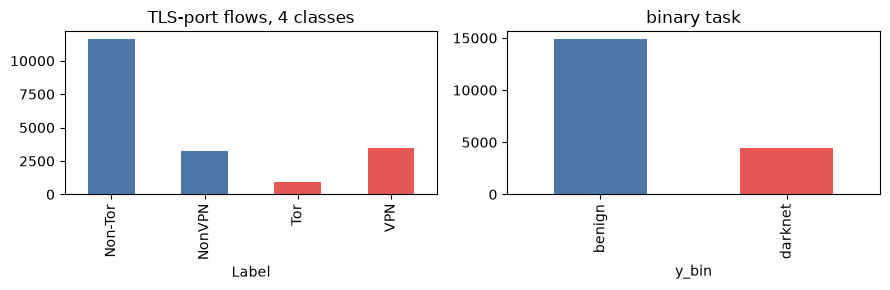

In [5]:
ID_COLS = ["Flow ID", "Src IP", "Src Port", "Dst IP", "Dst Port", "Timestamp", "Label", "Label.1"]
FEATURE_COLS = [c for c in raw.columns if c not in ID_COLS]

tls_mask = raw["Src Port"].isin(TLS_PORTS) | raw["Dst Port"].isin(TLS_PORTS)
df = raw[tls_mask].copy()
print(f"TLS-port flows: {len(df):,} of {len(raw):,}")

df[FEATURE_COLS] = df[FEATURE_COLS].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
n0 = len(df); df = df.dropna(subset=FEATURE_COLS); print("dropped for NaN/inf:", n0 - len(df))
n0 = len(df); df = df.drop_duplicates(subset=FEATURE_COLS + ["Label"]); print("dropped duplicates:", n0 - len(df))
df = df.reset_index(drop=True)

CLASSES_4 = ["Non-Tor", "NonVPN", "Tor", "VPN"]
df["y_4"]   = df["Label"].map({c: i for i, c in enumerate(CLASSES_4)})
df["y_bin"] = df["Label"].isin(["Tor", "VPN"]).astype(int)       # 1 = darknet (positive class)
print("flows kept:", len(df), "| numeric features:", len(FEATURE_COLS))
display(pd.crosstab(df["Label"], df["y_bin"], margins=True).rename(columns={0: "benign (0)", 1: "darknet (1)"}))

fig, ax = plt.subplots(1, 2, figsize=(9, 3))
df["Label"].value_counts().reindex(CLASSES_4).plot.bar(ax=ax[0], color=["#4c78a8", "#4c78a8", "#e45756", "#e45756"]); ax[0].set_title("TLS-port flows, 4 classes")
df["y_bin"].map({0: "benign", 1: "darknet"}).value_counts().plot.bar(ax=ax[1], color=["#4c78a8", "#e45756"]); ax[1].set_title("binary task")
plt.tight_layout(); plt.show()

## 3. Preprocessing pipeline (fitted on the training split only)

`prepare(seed, task)` performs, for one seed:

1. stratified sample of `N_TOTAL` flows (keeping the natural class imbalance) and a stratified 70/30 train/test split;
2. on the **training** part: drop constant columns, signed `log1p`, `StandardScaler`;
3. correlation-based selection of 11 features (largest absolute Pearson correlation with any class indicator, skipping near-duplicates);
4. SMOTE on the 11 scaled features (training set only; the test set keeps its natural imbalance);
5. PCA to 3 components fitted on the balanced training set, then `MinMaxScaler((0, pi))` fitted on it; test angles are clipped to [0, pi];
6. for the QGRU, the 11 scaled features are mapped to angles the same way, padded with one zero to 12 and cut into 4 steps of 3.

The test set only ever goes through `transform`.

In [6]:
def signed_log1p(a): return np.sign(a) * np.log1p(np.abs(a))

def select_by_correlation(Xs, y, k=N_FEATURES, thr=CORR_DECORR):
    """CHOICE: score = max over classes of |corr(feature, class indicator)|; greedy, skipping features correlated > thr with chosen ones."""
    Xc = Xs - Xs.mean(0); sd = Xs.std(0); sd[sd == 0] = 1
    score = np.zeros(Xs.shape[1])
    for c in np.unique(y):
        yc = (y == c).astype(float); yc = yc - yc.mean()
        if yc.std() == 0: continue
        score = np.maximum(score, np.abs((Xc * yc[:, None]).mean(0) / (sd * yc.std())))
    chosen = []
    corr = np.nan_to_num(np.corrcoef(Xs.T))
    for j in np.argsort(-score):
        if all(abs(corr[j, i]) < thr for i in chosen): chosen.append(j)
        if len(chosen) == k: break
    return np.array(chosen), score

def to_angles(scaler, Z): return np.clip(scaler.transform(Z), 0, np.pi)

def to_sequence(A):
    pad = np.zeros((len(A), SEQ_STEPS * N_QUBITS - A.shape[1])); return np.hstack([A, pad]).reshape(len(A), SEQ_STEPS, N_QUBITS)

def prepare(seed, task, verbose=False):
    ycol = "y_bin" if task == "binary" else "y_4"
    sub = df.groupby("Label", group_keys=False).sample(frac=min(1.0, N_TOTAL / len(df)), random_state=seed)
    tr, te = train_test_split(sub, test_size=TEST_SIZE, stratify=sub["Label"], random_state=seed)
    Xtr, Xte = tr[FEATURE_COLS].values.astype(float), te[FEATURE_COLS].values.astype(float)
    ytr, yte = tr[ycol].values, te[ycol].values
    keep = Xtr.std(0) > 0                                              # constant columns (training split)
    names = np.array(FEATURE_COLS)[keep]
    Xtr, Xte = signed_log1p(Xtr[:, keep]), signed_log1p(Xte[:, keep])
    sc = StandardScaler().fit(Xtr); Ztr, Zte = sc.transform(Xtr), sc.transform(Xte)
    idx, score = select_by_correlation(Ztr, ytr)
    Ztr, Zte, sel = Ztr[:, idx], Zte[:, idx], names[idx]
    kn = max(1, min(5, np.bincount(ytr).min() - 1))
    Zb, yb = SMOTE(random_state=seed, k_neighbors=kn).fit_resample(Ztr, ytr)
    pca = PCA(n_components=N_QUBITS, random_state=seed).fit(Zb)
    P_b, P_te = pca.transform(Zb), pca.transform(Zte)
    mm = MinMaxScaler((0, np.pi)).fit(P_b);   A_b, A_te = mm.transform(P_b), to_angles(mm, P_te)
    mm11 = MinMaxScaler((0, np.pi)).fit(Zb);  S_b, S_te = to_sequence(mm11.transform(Zb)), to_sequence(to_angles(mm11, Zte))
    if verbose:
        print(f"seed {seed} task {task}: train {len(ytr)} real -> {len(yb)} after SMOTE | test {len(yte)} | PCA variance kept {pca.explained_variance_ratio_.sum():.2f}")
        print("train counts before:", np.bincount(ytr), "after:", np.bincount(yb), "| test:", np.bincount(yte))
        print("selected features:", [str(s) for s in sel])
    return dict(x_tr=Zb.astype("float32"), x_te=Zte.astype("float32"), a_tr=A_b.astype("float32"), a_te=A_te.astype("float32"),
                s_tr=S_b.astype("float32"), s_te=S_te.astype("float32"), y_tr=yb, y_te=yte, sel=sel, n_classes=len(np.unique(ytr)),
                var=pca.explained_variance_ratio_.sum())

d0 = prepare(SEED, "binary", verbose=True)
d4 = prepare(SEED, "4class", verbose=True)

seed 42 task binary: train 5600 real -> 8630 after SMOTE | test 2400 | PCA variance kept 0.79
train counts before: [4315 1285] after: [4315 4315] | test: [1850  550]
selected features: ['Fwd Seg Size Min', 'Fwd Header Length', 'Fwd Act Data Pkts', 'FIN Flag Count', 'Bwd Packet/Bulk Avg', 'Total Length of Fwd Packet', 'Bwd Packet Length Min', 'Bwd Header Length', 'Fwd PSH Flags', 'Total Length of Bwd Packet', 'SYN Flag Count']
seed 42 task 4class: train 5600 real -> 13472 after SMOTE | test 2400 | PCA variance kept 0.86
train counts before: [3368  947  274 1011] after: [3368 3368 3368 3368] | test: [1444  406  117  433]
selected features: ['Fwd Act Data Pkts', 'Total Fwd Packet', 'Fwd Seg Size Min', 'Bwd Packet/Bulk Avg', 'Bwd Header Length', 'Total Length of Fwd Packet', 'Total Length of Bwd Packet', 'Bwd Init Win Bytes', 'Fwd PSH Flags', 'FWD Init Win Bytes', 'Fwd Packet Length Mean']


## 4. The quantum layer as a custom TensorFlow layer

The paper says its quantum layers are "custom TensorFlow layers with trainable weights, simulating quantum behavior". The class below does exactly that for
the circuit it names:

* `AngleEmbedding` (rotation X): qubit *q* starts in |0> and gets RX(x_q);
* `StronglyEntanglingLayers`: for each layer, a general rotation `Rot(phi, theta, omega)` on every qubit, then CNOTs from qubit *q* to qubit *(q + r) mod 3*,
  where the range *r* is `(layer mod 2) + 1` (PennyLane's default);
* read-out: the expectation value of Pauli-Z on every qubit, so 3 numbers in [-1, 1].

The 3-qubit state (8 complex amplitudes) is stored as a tensor `(batch, 2, 2, 2)` and every gate is a tensor contraction, so the whole layer is differentiable by
TensorFlow's autodiff and trains with Adam like any dense layer. The weight tensor has shape `(layers, qubits, 3)`. The same layer can also be applied at every step of a
sequence (input shape `(batch, steps, 3)`), which is what the QGRU needs.

In [7]:
class TFQuantumLayer(keras.layers.Layer):
    """Exact state-vector simulation of AngleEmbedding(rotation X) + StronglyEntanglingLayers + <Z> read-out, in TensorFlow ops."""
    def __init__(self, n_qubits=N_QUBITS, n_layers=N_LAYERS, **kw):
        super().__init__(**kw); self.n = n_qubits; self.L = n_layers
    def build(self, input_shape):
        self.w = self.add_weight(shape=(self.L, self.n, 3), name="sel_weights", trainable=True,
                                 initializer=keras.initializers.RandomUniform(0.0, 2 * np.pi))   # CHOICE: init range
    def compute_output_shape(self, input_shape): return tuple(input_shape[:-1]) + (self.n,)
    def _apply1(self, psi, U, q):                        # apply a 2x2 gate on qubit q of psi (batch, 2, ..., 2)
        out = tf.tensordot(psi, U, axes=[[q + 1], [1]])  # contracted axis is replaced by a new last axis
        rest = [a for a in range(self.n + 1) if a != q + 1] + [q + 1]
        return tf.transpose(out, [rest.index(a) for a in range(self.n + 1)])
    def _cnot(self, psi, c, t):
        p0, p1 = tf.unstack(psi, axis=c + 1)
        ta = t + 1 if t < c else t                       # position of the target axis after removing the control axis
        return tf.stack([p0, tf.reverse(p1, axis=[ta])], axis=c + 1)
    @staticmethod
    def _rot(phi, theta, omega):                         # Rot(phi, theta, omega) = RZ(omega) RY(theta) RZ(phi)
        c = tf.cast(tf.cos(theta / 2), tf.complex64); s = tf.cast(tf.sin(theta / 2), tf.complex64)
        ph, om = tf.cast(phi, tf.complex64), tf.cast(omega, tf.complex64); j = tf.constant(1j, tf.complex64)
        return tf.stack([tf.stack([tf.exp(-j * (ph + om) / 2) * c, -tf.exp(j * (ph - om) / 2) * s]),
                         tf.stack([tf.exp(-j * (ph - om) / 2) * s,  tf.exp(j * (ph + om) / 2) * c])])
    def call(self, x):
        lead = tf.shape(x)[:-1]
        xb = tf.reshape(tf.cast(x, tf.float32), (-1, self.n)); B = tf.shape(xb)[0]
        j = tf.constant(1j, tf.complex64)
        psi = tf.ones((B, 1), tf.complex64)
        for q in range(self.n):                          # product state RX(x_q)|0> = cos(x/2)|0> - i sin(x/2)|1>
            a = tf.stack([tf.cast(tf.cos(xb[:, q] / 2), tf.complex64), -j * tf.cast(tf.sin(xb[:, q] / 2), tf.complex64)], axis=1)
            psi = tf.reshape(psi[:, :, None] * a[:, None, :], (B, -1))
        psi = tf.reshape(psi, [-1] + [2] * self.n)
        for l in range(self.L):
            for q in range(self.n):
                psi = self._apply1(psi, self._rot(self.w[l, q, 0], self.w[l, q, 1], self.w[l, q, 2]), q)
            if self.n > 1:
                r = (l % (self.n - 1)) + 1
                for q in range(self.n): psi = self._cnot(psi, q, (q + r) % self.n)
        prob = tf.math.real(psi * tf.math.conj(psi))
        z = []
        for q in range(self.n):
            pq = tf.reduce_sum(prob, axis=[a for a in range(1, self.n + 1) if a != q + 1])
            z.append(pq[:, 0] - pq[:, 1])
        out = tf.reshape(tf.stack(z, axis=1), tf.concat([lead, [self.n]], 0))
        out.set_shape(x.shape[:-1].concatenate([self.n]))
        return out

# --- check 1: same numbers as PennyLane's default.qubit for the same circuit and weights
dev = qml.device("default.qubit", wires=N_QUBITS)
@qml.qnode(dev, interface="autograd")
def pl_circuit(x, w):
    qml.AngleEmbedding(x, wires=range(N_QUBITS), rotation="X")
    qml.StronglyEntanglingLayers(w, wires=range(N_QUBITS))
    return [qml.expval(qml.PauliZ(i)) for i in range(N_QUBITS)]

qlayer = TFQuantumLayer(); Xdemo = np.random.default_rng(0).uniform(0, np.pi, (6, N_QUBITS)).astype("float32")
tf_out = qlayer(Xdemo).numpy(); W = qlayer.w.numpy()
pl_out = np.array([[float(v) for v in pl_circuit(x, W)] for x in Xdemo])
print("max |TF layer - PennyLane| over 6 inputs x 3 qubits:", np.abs(tf_out - pl_out).max())
assert np.allclose(tf_out, pl_out, atol=1e-5)

# --- check 2: TensorFlow autodiff gradient w.r.t. the weights equals PennyLane's autodiff gradient
with tf.GradientTape() as tape:
    loss_tf = tf.reduce_sum(qlayer(Xdemo)[:, 0] * 1.0 + 0.5 * qlayer(Xdemo)[:, 2])
g_tf = tape.gradient(loss_tf, qlayer.w).numpy()
def pl_loss(w): return sum(pl_circuit(x, w)[0] + 0.5 * pl_circuit(x, w)[2] for x in Xdemo)
g_pl = qml.grad(pl_loss)(pnp.array(W, requires_grad=True))
print("max |gradient difference|:", np.abs(g_tf - np.array(g_pl)).max())
assert np.allclose(g_tf, np.array(g_pl), atol=1e-4)
print("sequence input (batch 2, 4 steps, 3) ->", qlayer(np.zeros((2, SEQ_STEPS, N_QUBITS), "float32")).shape)

max |TF layer - PennyLane| over 6 inputs x 3 qubits: 1.9448244192865616e-07


max |gradient difference|: 5.9604645e-07
sequence input (batch 2, 4 steps, 3) -> (2, 4, 3)


The paper also "visualized quantum circuits tested with sample inputs using Pauli-Z expectation plots". The next cell draws the circuit (PennyLane's drawer) and plots the three
Pauli-Z expectations as the first input angle sweeps from 0 to pi, with untrained random weights.

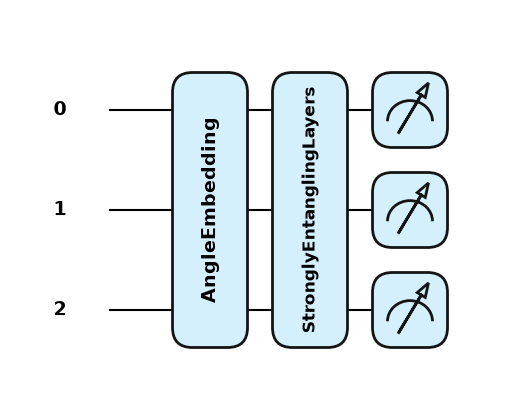

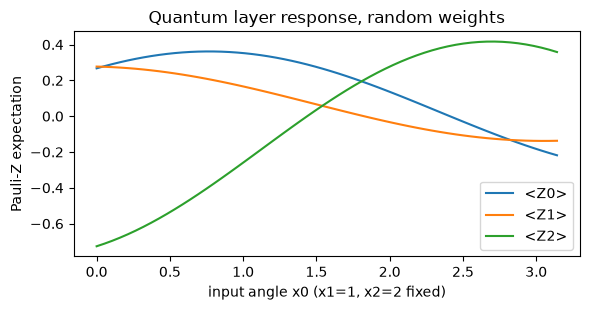

In [8]:
fig, _ = qml.draw_mpl(pl_circuit, style="pennylane")(Xdemo[0], W); plt.show()
sweep = np.linspace(0, np.pi, 60, dtype="float32")
X_sweep = np.stack([sweep, np.full_like(sweep, 1.0), np.full_like(sweep, 2.0)], axis=1)
Z_sweep = qlayer(X_sweep).numpy()
plt.figure(figsize=(6, 3.2))
for q in range(N_QUBITS): plt.plot(sweep, Z_sweep[:, q], label=f"<Z{q}>")
plt.xlabel("input angle x0 (x1=1, x2=2 fixed)"); plt.ylabel("Pauli-Z expectation"); plt.title("Quantum layer response, random weights")
plt.legend(); plt.tight_layout(); plt.show()

## 5. The models

All models end in a softmax over the classes and use the Adam optimiser with cross-entropy.

| Name | Inputs | Architecture |
|---|---|---|
| **HybridQNN** (the paper's QNN) | 11 scaled features + 3 PCA angles | classical branch Dense(32)-Dense(16) on the 11 features; quantum branch QLayer(3 PCA angles)-Dense(16); concatenate (fusion) -> Dense(16) -> softmax |
| **QNN-only** | 3 PCA angles | QLayer -> Dense(16) -> softmax |
| **Classical twin of QNN-only** | 3 PCA angles | Dense(8, tanh)-Dense(3, tanh) in place of the QLayer (also 3 numbers in [-1, 1], 59 parameters instead of 27) -> Dense(16) -> softmax |
| **QGRU** (the paper's QGRU) | 4 steps x 3 angles | QLayer applied at each step -> GRU(32, sequences) -> GRU(16) -> softmax |
| **GRU twin** | 4 steps x 3 angles | Dense(8, tanh)-Dense(3, tanh) at each step in place of the QLayer, the same GRU stack |
| RandomForest / SVC(rbf) | PCA(3) angles, and the 11 features | scikit-learn, 200 trees / C = 1 |

The QNN-only and QGRU models are the "pure" quantum-feature models: their only route from data to decision is the 3-qubit circuit's three numbers per step. The classical twins show
what the quantum layer adds, if anything, at the same width.

In [9]:
def build_model(kind, n_classes):
    qlayer_or_twin = lambda name: (TFQuantumLayer(name=name) if kind in ("qnn", "qgru")
                                   else keras.models.Sequential([keras.layers.Dense(8, activation="tanh"), keras.layers.Dense(N_QUBITS, activation="tanh")], name=name))
    if kind == "hybrid":
        x = keras.Input((N_FEATURES,), name="x"); a = keras.Input((N_QUBITS,), name="a")
        c = keras.layers.Dense(16, activation="relu")(keras.layers.Dense(32, activation="relu")(x))
        q = keras.layers.Dense(16, activation="relu")(TFQuantumLayer(name="qlayer")(a))
        f = keras.layers.Dense(16, activation="relu", name="fusion")(keras.layers.Concatenate()([c, q]))
        m = keras.Model([x, a], keras.layers.Dense(n_classes, activation="softmax")(f))
    elif kind in ("qnn", "qnn_twin"):
        a = keras.Input((N_QUBITS,), name="a")
        h = keras.layers.Dense(16, activation="relu")(qlayer_or_twin("feat")(a))
        m = keras.Model(a, keras.layers.Dense(n_classes, activation="softmax")(h))
    elif kind in ("qgru", "gru_twin"):
        s = keras.Input((SEQ_STEPS, N_QUBITS), name="s")
        h = qlayer_or_twin("feat")(s)
        h = keras.layers.GRU(32, return_sequences=True)(h); h = keras.layers.GRU(16)(h)
        m = keras.Model(s, keras.layers.Dense(n_classes, activation="softmax")(h))
    m.compile(optimizer=keras.optimizers.Adam(LR), loss="sparse_categorical_crossentropy")
    return m

INPUTS = {"hybrid": ["x", "a"], "qnn": ["a"], "qnn_twin": ["a"], "qgru": ["s"], "gru_twin": ["s"]}
NAMES  = {"hybrid": "HybridQNN (paper QNN)", "qnn": "QNN-only (3 angles)", "qnn_twin": "Classical twin of QNN-only",
          "qgru": "QGRU (paper)", "gru_twin": "GRU twin (no quantum)"}

def metrics(y, p):
    pr, rc, f1, _ = precision_recall_fscore_support(y, p, average="macro", zero_division=0)
    return dict(acc=accuracy_score(y, p) * 100, prec=pr * 100, rec=rc * 100, f1=f1 * 100,
                f1_w=f1_score(y, p, average="weighted", zero_division=0) * 100)

def train_keras(kind, d, seed):
    keras.utils.set_random_seed(seed)
    m = build_model(kind, d["n_classes"])
    pick = lambda split: [d[f"{k}_{split}"] for k in INPUTS[kind]]
    t0 = time.time()
    h = m.fit(pick("tr"), d["y_tr"], epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=0, shuffle=True)
    pred = m.predict(pick("te"), batch_size=512, verbose=0).argmax(1)
    return dict(model=NAMES[kind], pred=pred, sec=time.time() - t0, loss=h.history["loss"], n_params=m.count_params())

def train_sklearn(name, est, Xtr, Xte, d):
    t0 = time.time(); est.fit(Xtr, d["y_tr"]); return dict(model=name, pred=est.predict(Xte), sec=time.time() - t0, loss=None, n_params=None)

m_demo = build_model("hybrid", 2); m_demo.summary(print_fn=lambda s: print(s) if "Total params" in s or "qlayer" in s else None)

Model: "functional"
┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ x (InputLayer)      │ (None, 11)        │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ a (InputLayer)      │ (None, 3)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 32)        │        384 │ x[0][0]           │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ qlayer              │ (None, 3)         │         27 │ a[0][0]           │
│ (TFQuantumLayer)    │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 16)        │        528 │

## 6. Training and evaluation

For every task and seed the whole pipeline of section 3 runs again (sampling, split, SMOTE, PCA, initial weights), the five Keras models and the four scikit-learn
models are trained on the balanced training set, and everything is scored on the untouched, still imbalanced test split. This is the longest cell; progress is
printed for each run.

In [10]:
results, store = [], {}                 # store keeps predictions, histories and test labels of the first seed for the figures
t_start = time.time()
for task in TASKS:
    for seed in SEEDS:
        d = prepare(seed, task, verbose=(seed == SEEDS[0]))
        runs = [train_keras(k, d, seed) for k in ["hybrid", "qnn", "qnn_twin", "qgru", "gru_twin"]]
        runs += [train_sklearn("RandomForest (11 features)", RandomForestClassifier(200, random_state=seed, n_jobs=-1), d["x_tr"], d["x_te"], d),
                 train_sklearn("RandomForest (3 PCA angles)", RandomForestClassifier(200, random_state=seed, n_jobs=-1), d["a_tr"], d["a_te"], d),
                 train_sklearn("SVC rbf (11 features)", SVC(C=1.0, kernel="rbf", random_state=seed), d["x_tr"], d["x_te"], d),
                 train_sklearn("SVC rbf (3 PCA angles)", SVC(C=1.0, kernel="rbf", random_state=seed), d["a_tr"], d["a_te"], d)]
        for r in runs:
            results.append(dict(task=task, seed=seed, model=r["model"], seconds=r["sec"], **metrics(d["y_te"], r["pred"])))
            if seed == SEEDS[0]: store[(task, r["model"])] = dict(pred=r["pred"], y=d["y_te"], loss=r["loss"])
        print(f"[{task} seed {seed}] done, elapsed {(time.time() - t_start) / 60:.1f} min")
res = pd.DataFrame(results)
summary = (res.groupby(["task", "model"], sort=False)[["acc", "prec", "rec", "f1", "seconds"]].agg(["mean", "std"]).round(2))
display(summary)

seed 42 task binary: train 5600 real -> 8630 after SMOTE | test 2400 | PCA variance kept 0.79


train counts before: [4315 1285] after: [4315 4315] | test: [1850  550]
selected features: ['Fwd Seg Size Min', 'Fwd Header Length', 'Fwd Act Data Pkts', 'FIN Flag Count', 'Bwd Packet/Bulk Avg', 'Total Length of Fwd Packet', 'Bwd Packet Length Min', 'Bwd Header Length', 'Fwd PSH Flags', 'Total Length of Bwd Packet', 'SYN Flag Count']


[binary seed 42] done, elapsed 2.0 min


[binary seed 43] done, elapsed 4.5 min


[binary seed 44] done, elapsed 6.4 min


seed 42 task 4class: train 5600 real -> 13472 after SMOTE | test 2400 | PCA variance kept 0.86
train counts before: [3368  947  274 1011] after: [3368 3368 3368 3368] | test: [1444  406  117  433]
selected features: ['Fwd Act Data Pkts', 'Total Fwd Packet', 'Fwd Seg Size Min', 'Bwd Packet/Bulk Avg', 'Bwd Header Length', 'Total Length of Fwd Packet', 'Total Length of Bwd Packet', 'Bwd Init Win Bytes', 'Fwd PSH Flags', 'FWD Init Win Bytes', 'Fwd Packet Length Mean']


[4class seed 42] done, elapsed 9.6 min


[4class seed 43] done, elapsed 12.5 min


[4class seed 44] done, elapsed 15.7 min


acc         prec          rec           f1       seconds       
                                     mean   std   mean   std   mean   std   mean   std    mean    std
task   model                                                                                         
binary HybridQNN (paper QNN)        82.81  0.30  77.77  0.13  86.82  0.11  79.61  0.22   25.30   6.73
       QNN-only (3 angles)          82.38  1.12  76.19  0.50  82.31  1.20  77.96  0.56   21.43   5.28
       Classical twin of QNN-only   82.39  1.14  76.72  0.49  84.10  1.27  78.52  0.56    8.72   2.75
       QGRU (paper)                 82.04  1.22  77.29  0.82  86.54  0.54  78.91  1.13   36.12   5.95
       GRU twin (no quantum)        83.18  0.44  77.82  0.48  86.34  0.72  79.79  0.53   25.25   2.56
       RandomForest (11 features)   87.93  0.83  82.28  0.96  88.17  0.74  84.45  0.89    1.03   0.07
       RandomForest (3 PCA angles)  86.32  0.31  80.46  0.30  87.12  0.10  82.71  0.28    1.01   0.07
       SVC rbf (11 features)        83.71  0.36  78.16  0.34  86.34  0.47  80.24  0.39    3.79   0.52
       SVC rbf (3 PCA angles)       83.08  0.80  76.64  0.71  82.13  0.15  78.48  0.68    4.87   0.56
4class HybridQNN (paper QNN)        86.18  1.67  79.17  2.21  80.22  1.85  78.55  3.01   29.84   3.56
       QNN-only (3 angles)          78.54  0.94  68.23  0.60  71.07  1.49  68.19  1.43   26.65   3.01
       Classical twin of QNN-only   76.69  2.71  64.33  5.51  69.88  2.86  65.72  5.34   11.09   1.11
       QGRU (paper)                 86.25  1.15  78.52  1.78  80.25  1.62  79.07  1.92   59.99  10.37
       GRU twin (no quantum)        85.11  1.50  76.63  3.45  79.04  2.34  77.18  3.63   34.05   3.69
       RandomForest (11 features)   90.22  0.96  84.65  1.43  86.07  1.53  85.32  1.46    1.51   0.02
       RandomForest (3 PCA angles)  87.56  1.35  79.76  2.00  82.25  1.84  80.88  1.90    1.40   0.07
       SVC rbf (11 features)        86.18  1.16  80.55  1.69  79.96  1.90  80.14  1.74    8.99   0.66
       SVC rbf (3 PCA angles)       80.24  1.29  69.10  4.07  71.35  2.73  69.45  3.73   10.92   1.50

### Reading the table

`acc`, `prec`, `rec`, `f1` are test-set accuracy and macro-averaged precision, recall and F1 in percent (mean and standard deviation over the seeds; with a single seed the
standard deviation is NaN). `seconds` is training plus prediction time on this machine.

## 7. Figures: confusion matrices and training curves

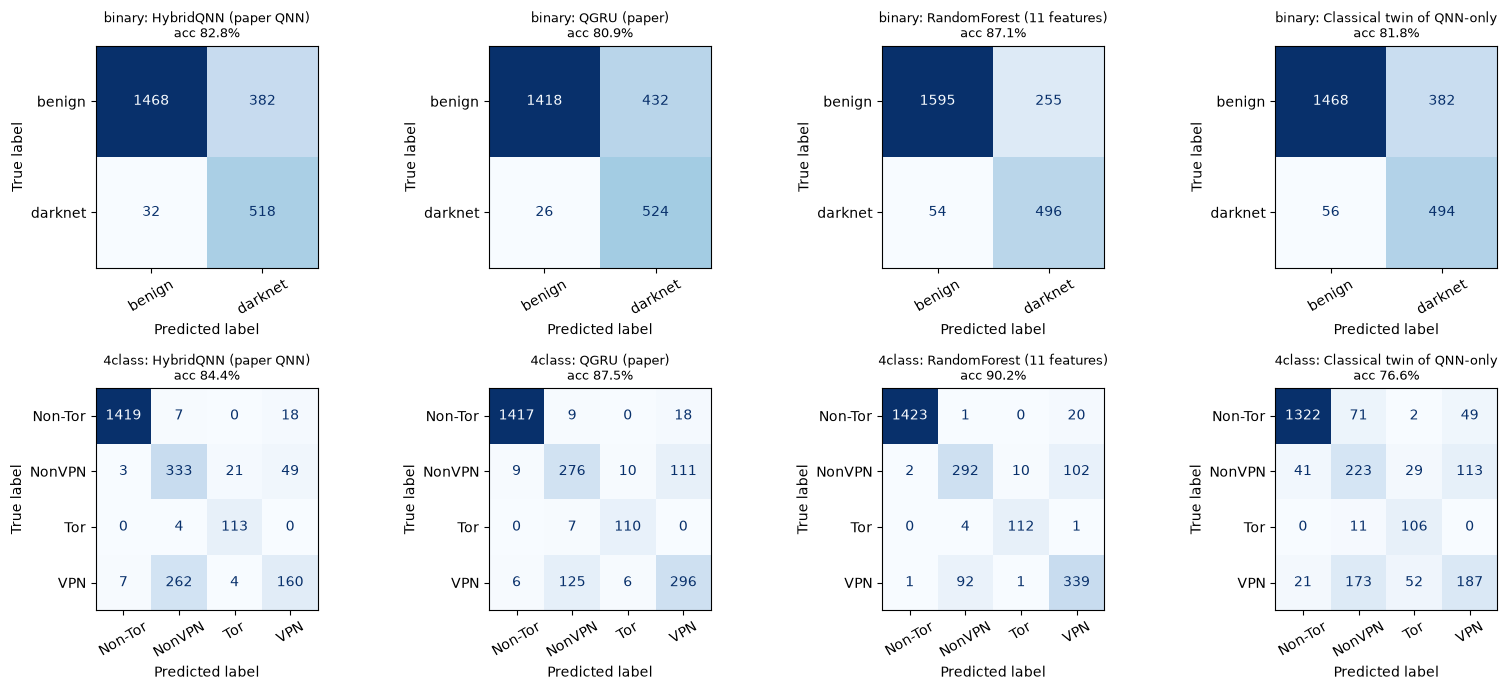

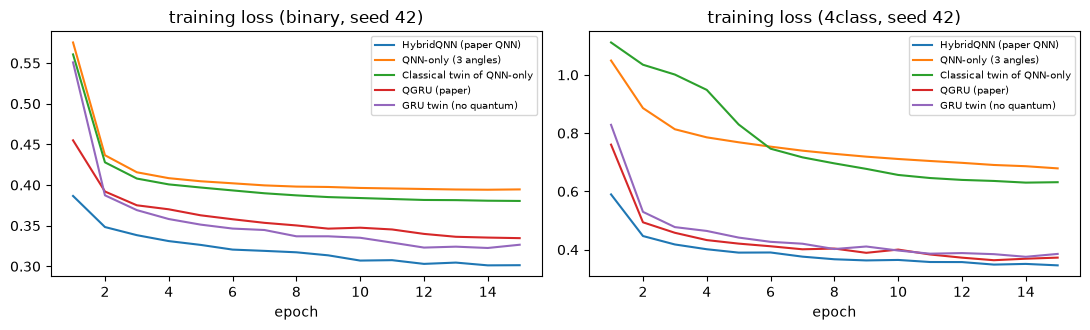

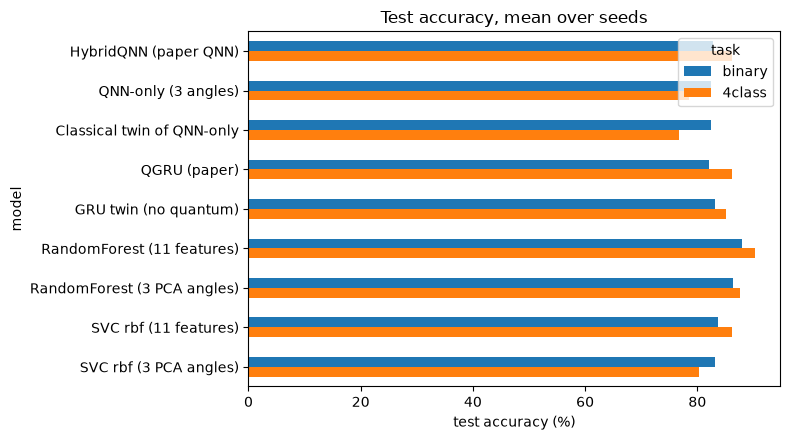

In [11]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for r, task in enumerate(TASKS):
    labels = ["benign", "darknet"] if task == "binary" else CLASSES_4
    for c, name in enumerate([NAMES["hybrid"], NAMES["qgru"], "RandomForest (11 features)", NAMES["qnn_twin"]]):
        s = store[(task, name)]
        ConfusionMatrixDisplay(confusion_matrix(s["y"], s["pred"]), display_labels=labels).plot(ax=axes[r, c], colorbar=False, cmap="Blues")
        axes[r, c].set_title(f"{task}: {name}\nacc {accuracy_score(s['y'], s['pred']) * 100:.1f}%", fontsize=9)
        axes[r, c].tick_params(axis="x", labelrotation=30)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=False)
for ax, task in zip(axes, TASKS):
    for k in ["hybrid", "qnn", "qnn_twin", "qgru", "gru_twin"]:
        ax.plot(range(1, EPOCHS + 1), store[(task, NAMES[k])]["loss"], label=NAMES[k])
    ax.set_title(f"training loss ({task}, seed {SEEDS[0]})"); ax.set_xlabel("epoch"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

piv = res.groupby(["task", "model"], sort=False)["acc"].mean().unstack(0)
piv.plot.barh(figsize=(8, 4.5)); plt.xlabel("test accuracy (%)"); plt.title("Test accuracy, mean over seeds"); plt.gca().invert_yaxis(); plt.tight_layout(); plt.show()

## 8. Does the quantum layer matter? (ablation on identical inputs)

The twins use exactly the same inputs and head, with a small tanh network (8 then 3 units) instead of the 3-qubit circuit. Their difference to the quantum models is the quantum layer's contribution.

In [12]:
ab = res.groupby(["task", "model"], sort=False)[["acc", "f1"]].mean().round(2)
rows = []
for task in TASKS:
    g = ab.loc[task]
    rows.append(dict(task=task, QNN_only_acc=g.loc[NAMES["qnn"], "acc"], classical_twin_acc=g.loc[NAMES["qnn_twin"], "acc"],
                     QGRU_acc=g.loc[NAMES["qgru"], "acc"], GRU_twin_acc=g.loc[NAMES["gru_twin"], "acc"],
                     HybridQNN_acc=g.loc[NAMES["hybrid"], "acc"], RF_11feat_acc=g.loc["RandomForest (11 features)", "acc"]))
ablation = pd.DataFrame(rows).set_index("task"); display(ablation)
for task in TASKS:
    a = ablation.loc[task]
    print(f"{task}: quantum - classical on 3 angles = {a.QNN_only_acc - a.classical_twin_acc:+.2f} points; "
          f"QGRU - GRU twin = {a.QGRU_acc - a.GRU_twin_acc:+.2f} points; HybridQNN - RF(11 features) = {a.HybridQNN_acc - a.RF_11feat_acc:+.2f} points")

,QNN_only_acc,classical_twin_acc,QGRU_acc,GRU_twin_acc,HybridQNN_acc,RF_11feat_acc
task,,,,,,
binary,82.38,82.39,82.04,83.18,82.81,87.93
4class,78.54,76.69,86.25,85.11,86.18,90.22


binary: quantum - classical on 3 angles = -0.01 points; QGRU - GRU twin = -1.14 points; HybridQNN - RF(11 features) = -5.12 points
4class: quantum - classical on 3 angles = +1.85 points; QGRU - GRU twin = +1.14 points; HybridQNN - RF(11 features) = -4.04 points


## 9. How can a 99.95 % come about? Duplicates, SMOTE before the split, and identifier columns

The clean pipeline above scores far below 99.95 %. The paper's description is compatible with a pipeline that differs in ways that all favour a high score:

1. **duplicate flows are kept** (about 20 % of the TLS-port flows are exact feature duplicates, so the same flow lands in both training and test set);
2. **SMOTE is applied before the train/test split**, so interpolated copies of training flows land in the test set;
3. **identifiers are encoded and kept** ("the entire data was encoded so that it is numeric"): flow id, IP addresses, ports and timestamp then become inputs, although they identify the capture session, not the behaviour.

Part A runs the HybridQNN and a random forest on the 11 selected flow features under the four combinations of (1) and (2). Part B (random forest only, all TLS-port flows) shows what
(1) and (3) do to the score of any model. This is not a recommended pipeline; it only shows what each shortcut does.

In [13]:
def run_literal(seed, dedup, smote_first):
    sub = raw[tls_mask].copy()
    sub[FEATURE_COLS] = sub[FEATURE_COLS].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
    sub = sub.dropna(subset=FEATURE_COLS)
    if dedup: sub = sub.drop_duplicates(subset=FEATURE_COLS + ["Label"])
    sub = sub.groupby("Label", group_keys=False).sample(frac=min(1.0, N_LITERAL / len(sub)), random_state=seed)
    y = sub["Label"].isin(["Tor", "VPN"]).astype(int).values
    X = signed_log1p(sub[FEATURE_COLS].values.astype(float)); keep = X.std(0) > 0; X = X[:, keep]
    Z = StandardScaler().fit_transform(X)                                           # fitted on ALL data
    idx, _ = select_by_correlation(Z, y); Z = Z[:, idx]                             # selected on ALL data
    if smote_first:
        Zs, ys = SMOTE(random_state=seed).fit_resample(Z, y)                        # SMOTE before the split
        Ztr, Zte, ytr, yte = train_test_split(Zs, ys, test_size=TEST_SIZE, stratify=ys, random_state=seed)
    else:
        Ztr, Zte, ytr, yte = train_test_split(Z, y, test_size=TEST_SIZE, stratify=y, random_state=seed)
        Ztr, ytr = SMOTE(random_state=seed).fit_resample(Ztr, ytr)
    pca = PCA(N_QUBITS, random_state=seed).fit(Ztr); mm = MinMaxScaler((0, np.pi)).fit(pca.transform(Ztr))
    d = dict(x_tr=Ztr.astype("float32"), x_te=Zte.astype("float32"), a_tr=mm.transform(pca.transform(Ztr)).astype("float32"),
             a_te=to_angles(mm, pca.transform(Zte)).astype("float32"), y_tr=ytr, y_te=yte, n_classes=2)
    out = {}
    q = train_keras("hybrid", d, seed); out["HybridQNN"] = metrics(yte, q["pred"])
    rf = train_sklearn("RF", RandomForestClassifier(200, random_state=seed, n_jobs=-1), d["x_tr"], d["x_te"], d); out["RandomForest"] = metrics(yte, rf["pred"])
    return out, len(y)

lit_rows = {}
for label, kw in {"duplicates kept, SMOTE before split (paper-compatible guess)": dict(dedup=False, smote_first=True),
                  "duplicates kept, SMOTE after split": dict(dedup=False, smote_first=False),
                  "duplicates removed, SMOTE before split": dict(dedup=True, smote_first=True),
                  "duplicates removed, SMOTE after split (clean)": dict(dedup=True, smote_first=False)}.items():
    out, n = run_literal(SEED, **kw)
    for mname, mt in out.items(): lit_rows[(label, mname)] = {k: round(v, 2) for k, v in mt.items() if k != "f1_w"}
literal = pd.DataFrame(lit_rows).T; display(literal)

acc   prec    rec     f1
duplicates kept, SMOTE before split (paper-comp... HybridQNN     89.85  90.58  89.85  89.81
                                                   RandomForest  92.29  92.32  92.29  92.29
duplicates kept, SMOTE after split                 HybridQNN     87.76  80.40  89.43  83.37
                                                   RandomForest  90.17  83.52  88.39  85.58
duplicates removed, SMOTE before split             HybridQNN     87.54  88.03  87.54  87.50
                                                   RandomForest  90.84  91.17  90.84  90.82
duplicates removed, SMOTE after split (clean)      HybridQNN     81.88  77.36  86.97  78.87
                                                   RandomForest  86.92  81.06  87.04  83.22

In [14]:
# Part B: random forest on ALL TLS-port flows, split first (70/30), different input sets. Identifier columns are label-encoded to numbers.
full = raw[tls_mask].copy()
full[FEATURE_COLS] = full[FEATURE_COLS].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
full = full.dropna(subset=FEATURE_COLS).reset_index(drop=True)
IDS = ["Flow ID", "Src IP", "Src Port", "Dst IP", "Dst Port", "Timestamp"]
enc = full[IDS + FEATURE_COLS].copy()
for c in IDS:
    if not pd.api.types.is_numeric_dtype(enc[c]): enc[c] = LabelEncoder().fit_transform(enc[c].astype(str))
yfull = full["Label"].isin(["Tor", "VPN"]).astype(int).values
dedup_mask = ~full.duplicated(subset=FEATURE_COLS + ["Label"]).values
rows = []
for name, cols, msk in [("flow features, duplicates removed", FEATURE_COLS, dedup_mask), ("flow features, duplicates kept", FEATURE_COLS, np.ones(len(full), bool)),
                        ("identifier columns only (flow id, IPs, ports, timestamp)", IDS, np.ones(len(full), bool)),
                        ("identifiers + flow features, duplicates kept", IDS + FEATURE_COLS, np.ones(len(full), bool))]:
    Xs, ys = enc.loc[msk, cols].values.astype(float), yfull[msk]
    xtr, xte, ytr, yte = train_test_split(Xs, ys, test_size=TEST_SIZE, stratify=ys, random_state=SEED)
    rf = RandomForestClassifier(100, random_state=SEED, n_jobs=-1).fit(xtr, ytr)
    rows.append(dict(inputs=name, flows=int(msk.sum()), rf_test_accuracy=round(rf.score(xte, yte) * 100, 2)))
display(pd.DataFrame(rows).set_index("inputs"))

,flows,rf_test_accuracy
inputs,,
"flow features, duplicates removed",19325,97.43
"flow features, duplicates kept",24029,97.63
"identifier columns only (flow id, IPs, ports, timestamp)",24029,100.00
"identifiers + flow features, duplicates kept",24029,99.93


Reading the two tables. Note first that Part B also shows how much the sample size matters: with all 19-24 thousand flows the flow features alone give about 97 % with a random forest, while the few thousand flows that a quantum simulation allows (Part A, and the main experiment) give 82-93 %. Part A: with the 11 correlation-selected flow features, keeping duplicates and applying SMOTE before the split change the score by the amounts shown, at the sample sizes used here.
Part B: on all TLS-port flows the *identifier columns alone* (which fix which machine produced which capture session) classify the two groups almost perfectly with an ordinary random forest, and so does anything that contains them.
Correlation-based selection does not pick identifiers, so if the paper's 99.95 % is real, plausible sources are identifiers among the inputs, or duplicates; the paper does not list its 11 features, so this cannot be confirmed.
It is a hypothesis about the paper, not a result of it.

## 10. Side by side with the paper

Verdict rule: "reproduced" if the notebook value is within 2 points (accuracy, precision, recall, F1 in percent) of the paper, "exceeded" or "not reached" otherwise with the gap.
The paper does not say which label set it used, so each claim is tested on the binary task (primary) and the 4-class task. Numbers are means over the seeds (clean pipeline).

In [15]:
paper = {"QNN":  dict(acc=99.95, prec=99.95, rec=99.95, f1=99.95),
         "QGRU": dict(acc=59.21, prec=53.24, rec=49.09, f1=45.84)}
mine = {"QNN": NAMES["hybrid"], "QGRU": NAMES["qgru"]}
rows = []
def verdict(p, n): return "reproduced" if abs(p - n) <= 2 else (f"exceeded (+{n - p:.1f})" if n > p else f"not reached ({n - p:.1f})")
for task in TASKS:
    for mdl in ["QNN", "QGRU"]:
        g = res[(res.task == task) & (res.model == mine[mdl])][["acc", "prec", "rec", "f1"]].mean()
        for k, lab in zip(["acc", "prec", "rec", "f1"], ["accuracy", "precision (macro)", "recall (macro)", "F1 (macro)"]):
            rows.append(dict(claim=f"{mdl} {lab}", task=task, paper=paper[mdl][k], notebook=round(g[k], 2), verdict=verdict(paper[mdl][k], g[k])))
comp = pd.DataFrame(rows)
# qualitative claims
for task in TASKS:
    a = lambda m: res[(res.task == task) & (res.model == m)]["acc"].mean()
    gap = a(NAMES["hybrid"]) - a(NAMES["qgru"])
    comp.loc[len(comp)] = dict(claim="QNN clearly better than QGRU (> 10 points)", task=task, paper="40.7 points", notebook=round(gap, 2),
                               verdict="reproduced" if gap > 10 else "not reached (gap " + f"{gap:.1f} points)")
    gapc = a(NAMES["hybrid"]) - a("RandomForest (11 features)")
    comp.loc[len(comp)] = dict(claim="quantum hybrid beats traditional ML (vs RandomForest, 11 features)", task=task, paper="stated, no numbers",
                               notebook=round(gapc, 2), verdict="not reached (hybrid is " + f"{gapc:+.2f} points vs RF)" if gapc < 0.5 else f"reproduced ({gapc:+.2f} points)")
comp.loc[len(comp)] = dict(claim="QGRU overfits / generalises poorly", task="both", paper="stated, no train curves", notebook="see section 7",
                           verdict="cannot be checked from the paper; see notebook loss curves and test scores")
comp.loc[len(comp)] = dict(claim="quantum run time 'efficient'", task="both", paper="no numbers", notebook="see seconds column", verdict="cannot be checked")
display(comp)

,claim,task,paper,notebook,verdict
0,QNN accuracy,binary,99.95,82.81,not reached (-17.1)
1,QNN precision (macro),binary,99.95,77.77,not reached (-22.2)
2,QNN recall (macro),binary,99.95,86.82,not reached (-13.1)
3,QNN F1 (macro),binary,99.95,79.61,not reached (-20.3)
4,QGRU accuracy,binary,59.21,82.04,exceeded (+22.8)
5,QGRU precision (macro),binary,53.24,77.29,exceeded (+24.0)
6,QGRU recall (macro),binary,49.09,86.54,exceeded (+37.5)
7,QGRU F1 (macro),binary,45.84,78.91,exceeded (+33.1)
8,QNN accuracy,4class,99.95,86.18,not reached (-13.8)
9,QNN precision (macro),4class,99.95,79.17,not reached (-20.8)


In [16]:
lit = literal.loc[("duplicates kept, SMOTE before split (paper-compatible guess)", "HybridQNN")]
print("Paper-compatible guess (section 9, part A), HybridQNN, binary task: accuracy", lit["acc"], "| paper 99.95 ->", verdict(99.95, lit["acc"]))
print("Clean pipeline, HybridQNN, binary task: accuracy",
      round(res[(res.task == "binary") & (res.model == NAMES["hybrid"])]["acc"].mean(), 2))
print(f"Total wall-clock time of the training cell: {(time.time() - t_start) / 60:.1f} min")

Paper-compatible guess (section 9, part A), HybridQNN, binary task: accuracy 89.85 | paper 99.95 -> not reached (-10.1)
Clean pipeline, HybridQNN, binary task: accuracy 82.81
Total wall-clock time of the training cell: 17.7 min


## 11. Reading the paper critically

* **The label set and the metric averaging are not stated.** Without them the 99.95 % (all four metrics identical) and the QGRU row (recall below accuracy) cannot be matched to a task; this notebook shows both the
  binary and the 4-class reading.
* **Evaluation protocol.** The paper says SMOTE was applied but not whether before or after splitting, nor whether identifiers survived "encoding all data to numeric". Section 9 shows that duplicates and identifier columns lift a random forest from about 85-98 % to 99.9 %. A 99.95 % is far above what the clean flow-feature pipelines of this notebook reach, which is why the data handling (identifiers, duplicates, SMOTE order) and the sample size are the first suspects.
* **The quantum part is small.** A 3-qubit circuit yields three numbers per input; the hybrid network also gets the 11 classical features in a parallel branch, so it can reach its score without the circuit.
  The twin experiment (section 8) is the fair test of the quantum layer, and the paper does not run it. A strong classical baseline (random forest) is also missing from the paper.
* **QGRU design.** A flow-feature vector is not a time series. Cutting 11 statistics into "time steps" gives a recurrent network no temporal structure to exploit; the paper's explanation (quantum
  embeddings are high dimensional) is not tested, and 59 % may equally be an optimisation or data-shape problem. The result is nonetheless reported honestly in the paper, which is to its credit.
* **No hardware, no noise.** Everything is a noiseless simulation; claims about efficiency or quantum advantage cannot be drawn.
* **Reproducibility.** There is no code, no hyper-parameter list, no seed and no confidence interval. The dataset is public, so a rerun is possible, but only under assumptions such as the ones made here.

## 12. Exercises

1. Change `N_LAYERS` to 1, 2 and 5. Does the QNN-only model (section 8) improve, and does it ever beat its classical twin?
2. Add a fourth and fifth qubit (`N_QUBITS = 5`, PCA to 5). Which parts of the notebook must change for the QGRU sequence layout (hint: `SEQ_STEPS`)?
3. In section 9 add a fifth variant: identifiers kept, but only the Src Port column removed. Which identifier column matters most? (Use feature importances of the random forest.)
4. Replace the sequence layout of the QGRU by a *real* sequence: group flows of the same source IP in time order and feed 4 consecutive flows. Does the QGRU now beat its GRU twin?
5. Replace `TFQuantumLayer` by `qml.qnn.KerasLayer` around `pl_circuit` and compare training time and results. What is the price of using PennyLane's simulator inside the training loop?